In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd, numpy as np

BASE = '/content/drive/MyDrive/mnc-analytics/'
v = pd.read_csv(BASE + 'clean/yt_videos_clean_tahap2.csv')
r = pd.read_csv(BASE + 'clean/app_reviews_clean.csv')
print('videos :', v.shape)    # expect (106303, 37)
print('reviews:', r.shape)    # expect (46649, 37)

print('\ngenre counts:')
print(v['content_genre'].value_counts().to_string())

obs = v['title'].str.upper().str.contains('OBSESI', na=False)
print('\nObsesi still in Sinetron:',
      (obs & v['content_genre'].eq('Sinetron & FTV')).sum(), '(expect 0)')

print('\nexclude_perf:', v['exclude_perf'].sum(), '(expect 23)',
      '| promo:', v['is_promo'].sum())

neg = r[r['score'] <= 2]
print('\nprimary complaint topic, negative reviews (%):')
print((pd.crosstab(neg['complaint_topic'], neg['app'],
                   normalize='columns') * 100).round(1).to_string())

Mounted at /content/drive
videos : (106303, 37)
reviews: (46649, 37)

genre counts:
content_genre
Sinetron & FTV           40705
Variety & Lifestyle      24254
Berita                   19624
Talent & Reality Show     7651
Lainnya                   3694
Infotainment              3150
Olahraga                  2764
Religi                    1845
Tidak teridentifikasi     1783
Promo & Korporat           833

Obsesi still in Sinetron: 16 (expect 0)

exclude_perf: 23 (expect 23) | promo: 833

primary complaint topic, negative reviews (%):
app                  RCTIplus  Vidio  Visionplus
complaint_topic                                 
akses_setelah_bayar      16.8   23.0        45.2
error_crash               5.6    3.0         3.0
gagal_putar               4.1    2.3         1.8
iklan                     8.0   14.6         2.9
konten                    4.9    6.6         4.4
lag_buffering             8.9    7.4         4.1
lainnya                  36.1   21.3        22.8
login_akun         

In [ ]:
print(v.loc[obs & v['content_genre'].eq('Sinetron & FTV'), 'title'].head(16).to_string())

18044    Anak Durhaka Yang Terobsesi Kaya Raya | FTV KU...
18405    Terobsesi Kaya Raya Bikin Perempuan Cantik Gel...
22156    PENASARAN INFO SERU DARI SELEBRITI  DISINI TEM...
22768    KEPOIN TERUS INFO TERKINI SEPUTAR SELEBRITI!  ...
22894    Terobsesi Gaya Hidup Mewah, Harta Teman Pun Di...
22986    Terobsesi Gaya Hidup Mewah, Harta Teman Pun Di...
23177    JANGAN KETINGGALAN INFO TERKINI SEPUTAR SELEBR...
23839    Hanya Karena Terobsesi Kaya, Rela Mengorbankan...
23870    JANGAN KETINGGALAN INFO TERKINI SEPUTAR SELEBR...
24375    TEROBSESI KAYA! Pengasuh Anakku Hancurkan Kelu...
24573    JANGAN KETINGGALAN INFO TERKINI SEPUTAR SELEBR...
25011    NGOBROL SEPUTAR SELEBRITI YA CUMA DISINI!   SE...
33171    Pacar Clara Terobsesi Menguasai Ilmu Polosit! ...
33195    Pacar Clara Terobsesi Menguasai Ilmu Polosit! ...
80292    Pak Aditya benar-benar terobsesi dengan Cintya...
80378    Siapa Yang Terobsesi Menghancurkan Rumah Tangg...


In [ ]:
p = v[~v['exclude_perf'] & ~v['is_promo']].copy()
print('performance rows:', len(p))

ch = p.groupby(['group', 'channel_name']).agg(
    videos=('video_id', 'size'),
    total_views=('views', 'sum'),
    median_views=('views', 'median'),
    median_vpd=('views_per_day', 'median'),
    median_er=('engagement_rate', 'median'),
).reset_index()
ch['share_videos_%'] = ch['videos'] / ch['videos'].sum() * 100
ch['share_views_%'] = ch['total_views'] / ch['total_views'].sum() * 100
ch['views_per_video'] = ch['total_views'] / ch['videos']
print(ch.sort_values('total_views', ascending=False)
        .round(1).to_string(index=False))

g = ch.groupby('group')[['videos', 'total_views']].sum()
print('\nshare by group (%):')
print((g / g.sum() * 100).round(1))

performance rows: 105447
     group channel_name  videos  total_views  median_views  median_vpd  median_er  share_videos_%  share_views_%  views_per_video
Kompetitor     Indosiar    7352   1779588074       77859.5       491.0        1.1             7.0           37.3         242055.0
Kompetitor         SCTV    8595    842623374       58432.0       362.8        1.3             8.2           17.7          98036.5
       MNC        iNews   19948    734880467        9194.0        92.9        0.8            18.9           15.4          36839.8
Kompetitor       Trans7   10167    658874100        3915.0        36.3        1.0             9.6           13.8          64805.2
Kompetitor     Trans TV   13735    270410746        2066.0        26.9        0.8            13.0            5.7          19687.7
       MNC        MNCTV   19516    212497024        1184.5         7.5        0.6            18.5            4.5          10888.3
       MNC         RCTI    6639    176429773        3299.0       

In [ ]:
fmt = p[p['format'].isin(['Shorts', 'Clip', 'Full', 'Live/Streaming'])]

t = fmt.groupby(['group', 'format']).agg(
    videos=('video_id', 'size'),
    median_views=('views', 'median'),
    median_vpd=('views_per_day', 'median'),
    median_er=('engagement_rate', 'median'),
)
t['share_%'] = (t['videos'] /
                t.groupby(level='group')['videos'].transform('sum') * 100)
print(t.round(2).to_string())

print('\nmedian views per day, channel x format:')
print(fmt.pivot_table(index='channel_name', columns='format',
                      values='views_per_day', aggfunc='median')
         .round(1).to_string())

print('\nShorts share of uploads per channel (%):')
print((fmt['format'].eq('Shorts').groupby(fmt['channel_name']).mean()
       * 100).round(1))

                           videos  median_views  median_vpd  median_er  share_%
group      format                                                              
Kompetitor Clip             11380        2447.5       22.46       1.01    28.56
           Full             11994       30414.0      219.18       1.05    30.10
           Live/Streaming     130      111423.0     1418.28       0.69     0.33
           Shorts           16345       15704.0      126.59       0.99    41.02
MNC        Clip             19705         818.0        5.56       0.65    30.04
           Full             29391        1309.0        8.70       0.74    44.80
           Live/Streaming    6954        6055.0       53.44       0.78    10.60
           Shorts            9548        5836.5       38.56       0.77    14.56

median views per day, channel x format:
format         Clip   Full  Live/Streaming  Shorts
channel_name                                      
GTV             1.8    2.3             4.6    20.4
Indosi

In [ ]:
p['vpd_index'] = (p['views_per_day'] /
    p.groupby('channel_name')['views_per_day'].transform('median'))

def slot(h):
    if 5 <= h <= 10:  return '1 Pagi 05-10'
    if 11 <= h <= 14: return '2 Siang 11-14'
    if 15 <= h <= 18: return '3 Sore 15-18'
    if 19 <= h <= 22: return '4 Prime 19-22'
    return '5 Malam 23-04'
p['slot'] = p['hour'].map(slot)

for col in [['slot'], ['dow_num', 'day_of_week']]:
    t = p.groupby(['group'] + col).agg(
        videos=('video_id', 'size'),
        median_vpd=('views_per_day', 'median'),
        perf_index=('vpd_index', 'median'))
    print(t.round(2).to_string(), '\n')

for grp in ['MNC', 'Kompetitor']:
    g = p[p['group'] == grp]
    s = g.groupby(['day_of_week', 'hour']).agg(
        n=('video_id', 'size'), idx=('vpd_index', 'median'))
    print(f'top 8 day x hour slots, {grp} (min 100 videos):')
    print(s[s['n'] >= 100].sort_values('idx', ascending=False)
           .head(8).round(2).to_string(), '\n')

                          videos  median_vpd  perf_index
group      slot                                         
Kompetitor 1 Pagi 05-10     7066      188.58        1.98
           2 Siang 11-14   11389       77.93        0.85
           3 Sore 15-18    13269       37.01        0.58
           4 Prime 19-22    5939      357.60        1.57
           5 Malam 23-04    2186      481.50        1.73
MNC        1 Pagi 05-10     9100       22.72        1.07
           2 Siang 11-14   16311       15.90        1.47
           3 Sore 15-18    19215        9.05        0.91
           4 Prime 19-22   16011       11.53        0.83
           5 Malam 23-04    4961        9.16        0.76 

                                videos  median_vpd  perf_index
group      dow_num day_of_week                                
Kompetitor 0       Monday         7260       91.76        0.83
           1       Tuesday        7302       92.54        0.98
           2       Wednesday      6683       96.47        0.96

In [ ]:
p['vpd_index2'] = (p['views_per_day'] /
    p.groupby(['channel_name', 'format'])['views_per_day'].transform('median'))

for col in [['slot'], ['dow_num', 'day_of_week']]:
    t = p.groupby(['group'] + col)['vpd_index2'].median().unstack(0)
    print(t.round(2).to_string(), '\n')

g = p[p['group'] == 'MNC']
s = g.groupby(['day_of_week', 'hour']).agg(
    n=('video_id', 'size'), idx=('vpd_index2', 'median'))
print('top MNC slots (format-adjusted):')
print(s[s['n'] >= 100].sort_values('idx', ascending=False).head(8).round(2))

for d, h in [('Sunday', 7), ('Wednesday', 0)]:
    x = g[(g['day_of_week'] == d) & (g['hour'] == h)]
    print(f'\nwhat MNC posts {d} {h}:00')
    print(x.groupby(['channel_name', 'format', 'content_genre']).size()
           .sort_values(ascending=False).head(4).to_string())

group          Kompetitor   MNC
slot                           
1 Pagi 05-10         1.70  1.07
2 Siang 11-14        0.90  1.06
3 Sore 15-18         0.79  1.04
4 Prime 19-22        1.27  0.93
5 Malam 23-04        1.34  0.84 

group                Kompetitor   MNC
dow_num day_of_week                  
0       Monday             0.88  0.96
1       Tuesday            0.96  1.05
2       Wednesday          0.94  0.88
3       Thursday           1.01  0.96
4       Friday             1.11  0.97
5       Saturday           1.24  1.15
6       Sunday             1.05  1.36 

top MNC slots (format-adjusted):
                    n   idx
day_of_week hour           
Wednesday   0     149  3.30
Sunday      7     460  2.63
Saturday    7     478  2.18
Sunday      12    257  2.04
            15    242  2.02
            8     319  1.96
            21    194  1.85
Friday      12    423  1.76

what MNC posts Sunday 7:00
channel_name  format  content_genre 
GTV           Shorts  Sinetron & FTV    118
        

In [ ]:
gp = p[~p['content_genre'].isin(['Lainnya', 'Tidak teridentifikasi'])]

t = gp.groupby(['group', 'content_genre']).agg(
    videos=('video_id', 'size'),
    median_vpd=('views_per_day', 'median'),
    perf_index=('vpd_index2', 'median'))
t['share_%'] = (t['videos'] /
                t.groupby(level='group')['videos'].transform('sum') * 100)
print(t.round(2).to_string(), '\n')

pv = gp.pivot_table(index='content_genre', columns='channel_name',
                    values='views_per_day', aggfunc='median')
n = gp.pivot_table(index='content_genre', columns='channel_name',
                   values='video_id', aggfunc='size')
print('median views/day, channel x genre (only cells with 50+ videos):')
print(pv.where(n >= 50).round(1).to_string())

                                  videos  median_vpd  perf_index  share_%
group      content_genre                                                 
Kompetitor Berita                     60       94.02        0.81     0.17
           Infotainment             2186       87.25        1.71     6.04
           Olahraga                 1923      243.47        0.74     5.31
           Religi                   1276        9.95        0.36     3.53
           Sinetron & FTV           7878      476.26        1.12    21.77
           Talent & Reality Show    2811      457.13        0.98     7.77
           Variety & Lifestyle     20055       27.53        0.95    55.42
MNC        Berita                  19563       88.80        1.00    30.67
           Infotainment              964        3.06        0.56     1.51
           Olahraga                  841       26.79        0.65     1.32
           Religi                    568        5.50        0.21     0.89
           Sinetron & FTV          328

In [ ]:
x = p[(p['channel_name'] == 'iNews') & (p['content_genre'] == 'Sinetron & FTV')]
print(len(x), x['genre_rule'].value_counts().to_dict())
print(x['title'].sample(min(8, len(x)), random_state=1).tolist())

114 {'episode_marker': 110, 'sinetron': 4}
['Jelang "Deadline Hormuz" AS Bombardir Iran? Iran Akan Berikan Balasan Yang Lebih Berat | iSore (7/4)', '🔴LIVE | Kuasa Hukum Temukan 9 Keanehan, Eks Jampidsus Febrie Ajukan 2 Praperadilan | (5/8)', '🔴[LIVE] Lautan Manusia Sambut Kedatangan Jenazah Pemimpin Iran Ali Khamenei di Karbala, Irak (8/7)', 'Prabowo Bongkar Rekening Siluman Koruptor Buat Peliharaan atau Istri Muda', 'BREAKING! Iran Rudal 2 Kapal Perusak AS | BN (7/6)', 'Serangan Israel Guncang Lebanon Selatan, Serangan Udara Hantam Sejumlah Gedung | FULL (1/4)', '3 TNI Gugur, Dubes Palestina Takziah: Kehilangan Kapten Zulmi adalah Duka Bersama |iTerkini (2/4)', '🔴 [LIVE] PRESIDEN PRABOWO - NARENDRA MODI SAKSIKAN PENANDATANGANAN KERJASAMA INDONESIA - INDIA (7/7)']


In [ ]:

r['review_dt'] = pd.to_datetime(r['review_dt'])
w = r[r['review_dt'] >= '2025-01-01'].copy()
w['quarter'] = w['review_dt'].dt.to_period('Q').astype(str)
nw = w[~w['is_spike_day']]
print('reviews in window:', w.groupby('app').size().to_dict())
print('spike days in window:', w[w['is_spike_day']]
      .groupby('app')['review_date'].nunique().to_dict())

print('\nrating summary, no spike days:')
print(nw.groupby('app')['score'].agg(
    avg='mean',
    pct_1star=lambda s: (s == 1).mean() * 100,
    pct_neg=lambda s: (s <= 2).mean() * 100).round(2))

print('\naverage score per quarter, no spike days:')
print(nw.pivot_table(index='quarter', columns='app',
                     values='score', aggfunc='mean').round(2))

reviews in window: {'RCTIplus': 4884, 'Vidio': 17860, 'Visionplus': 4259}
spike days in window: {'RCTIplus': 5, 'Vidio': 4, 'Visionplus': 4}

rating summary, no spike days:
             avg  pct_1star  pct_neg
app                                 
RCTIplus    2.49      54.82    60.96
Vidio       2.79      44.36    52.02
Visionplus  3.17      39.60    44.38

average score per quarter, no spike days:
app      RCTIplus  Vidio  Visionplus
quarter                             
2025Q1       2.25   2.98        3.08
2025Q2       2.03   2.89        3.52
2025Q3       3.56   2.75        3.73
2025Q4       1.91   2.85        2.66
2026Q1       2.61   2.81        2.56
2026Q2       2.15   2.55        3.23
2026Q3       2.88   2.57        2.90
2026Q4       2.56   2.50        2.51


In [ ]:
neg = w[w['score'] <= 2]
nn = neg[~neg['is_spike_day']]

print('H6 reply behaviour, negative reviews, no spike days:')
print(nn.groupby('app').agg(
    reply_rate=('replied', 'mean'),
    median_hours=('reply_hours', 'median')).round(2))
print(nn[nn['replied']].groupby('app')['reply_is_template']
      .mean().round(2).rename('template_share_of_replies'))

print('\nH1 share of negative reviews mentioning sport (%):')
print((neg.groupby('app')['mentions_sport'].mean() * 100).round(1))

print('\n"paid but can\'t watch" rate (%), sport vs non-sport:')
print((neg.groupby(['app', 'mentions_sport'])['is_akses_setelah_bayar']
       .mean().unstack() * 100).round(1))

H6 reply behaviour, negative reviews, no spike days:
            reply_rate  median_hours
app                                 
RCTIplus          0.44         41.55
Vidio             0.96          1.54
Visionplus        0.99          0.66
app
RCTIplus      0.86
Vidio         0.48
Visionplus    0.60
Name: template_share_of_replies, dtype: float64

H1 share of negative reviews mentioning sport (%):
app
RCTIplus      10.9
Vidio          8.8
Visionplus    19.9
Name: mentions_sport, dtype: float64

"paid but can't watch" rate (%), sport vs non-sport:
mentions_sport  False  True 
app                         
RCTIplus         16.8   46.0
Vidio            21.9   36.0
Visionplus       31.5   54.9


In [ ]:
import matplotlib.pyplot as plt, os
from matplotlib.lines import Line2D

# 1. fix: iNews news videos mislabelled as Sinetron (date "(7/4)" read as part)
m = (v['channel_name'] == 'iNews') & v['content_genre'].eq('Sinetron & FTV')
idx = m[m].index
v.loc[idx, ['content_genre', 'genre_rule']] = ['Berita', 'fix_inews_news']
pidx = idx.intersection(p.index)
p.loc[pidx, ['content_genre', 'genre_rule']] = ['Berita', 'fix_inews_news']
v.to_csv(BASE + 'clean/yt_videos_clean_tahap2.csv', index=False)
print('iNews rows fixed:', len(idx))

# 2. chart style (same colours in every chart)
FIG = BASE + 'docs/figures/'
os.makedirs(FIG, exist_ok=True)
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
GROUP_C = {'MNC': BLUE, 'Kompetitor': ORANGE}
APP_C = {'RCTIplus': BLUE, 'Visionplus': AQUA, 'Vidio': ORANGE}
APP_NAME = {'RCTIplus': 'RCTI+', 'Visionplus': 'Vision+', 'Vidio': 'Vidio'}
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GRID, 'axes.labelcolor': MUTED,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.grid': True,
    'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'legend.frameon': False})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG + name, bbox_inches='tight', facecolor='white')
    plt.show()
print('style ready')

iNews rows fixed: 114
style ready


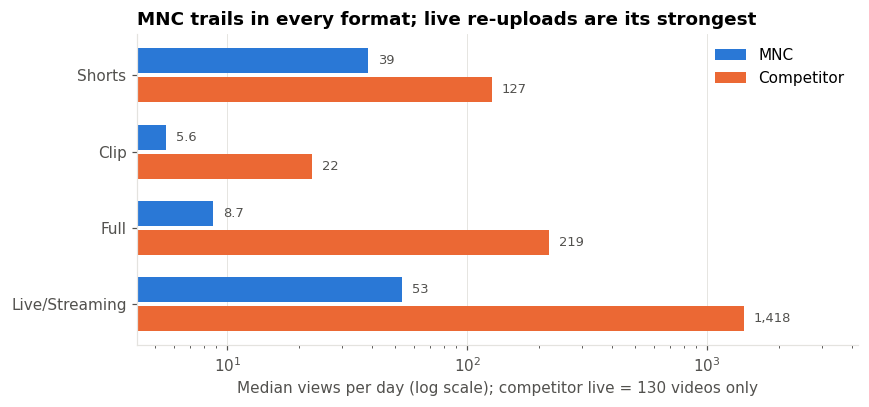

In [ ]:
order = ['Live/Streaming', 'Full', 'Clip', 'Shorts']
f2 = fmt.groupby(['format', 'group'])['views_per_day'].median()
f2 = f2.unstack().loc[order]
fig, ax = plt.subplots(figsize=(8, 3.8))
h = 0.38
for grp, off, lab in [('MNC', h / 2, 'MNC'),
                      ('Kompetitor', -h / 2, 'Competitor')]:
    ypos = np.arange(len(f2)) + off
    ax.barh(ypos, f2[grp], height=h - 0.05, color=GROUP_C[grp], label=lab)
    for yy, val in zip(ypos, f2[grp]):
        txt = f'{val:,.1f}' if val < 10 else f'{val:,.0f}'
        ax.text(val * 1.1, yy, txt, va='center', fontsize=8.5, color=MUTED)
ax.set_xscale('log')
ax.set_yticks(range(len(f2)), f2.index)
ax.set_xlim(right=f2.values.max() * 3)
ax.set_xlabel('Median views per day (log scale); competitor live = 130 videos only')
ax.grid(axis='y', visible=False)
ax.set_title('MNC trails in every format; live re-uploads are its strongest')
ax.legend(loc='upper right')
save(fig, '02_format_views_per_day.png')

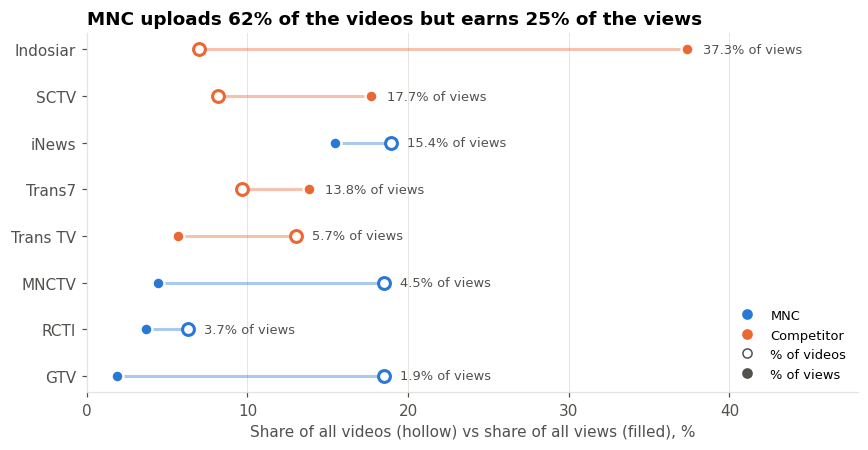

In [ ]:
c1 = ch.rename(columns={'share_videos_%': 'sv', 'share_views_%': 'sw'})
c1 = c1.sort_values('sw').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 4.2))
for i, row in c1.iterrows():
    col = GROUP_C[row['group']]
    ax.plot([row['sv'], row['sw']], [i, i], color=col, lw=2, alpha=0.4)
    ax.scatter(row['sv'], i, s=60, facecolor='white', edgecolor=col,
               lw=2, zorder=3)
    ax.scatter(row['sw'], i, s=60, color=col, edgecolor='white',
               lw=1.5, zorder=3)
    ax.text(max(row['sv'], row['sw']) + 1, i, f"{row['sw']:.1f}% of views",
            va='center', fontsize=8.5, color=MUTED)
ax.set_yticks(range(len(c1)), c1['channel_name'])
ax.set_xlim(0, 48)
ax.set_xlabel('Share of all videos (hollow) vs share of all views (filled), %')
ax.grid(axis='y', visible=False)
ax.set_title('MNC uploads 62% of the videos but earns 25% of the views')
leg = [Line2D([], [], marker='o', ls='', color=BLUE, label='MNC'),
       Line2D([], [], marker='o', ls='', color=ORANGE, label='Competitor'),
       Line2D([], [], marker='o', ls='', mfc='white', mec=MUTED,
              label='% of videos'),
       Line2D([], [], marker='o', ls='', color=MUTED, label='% of views')]
ax.legend(handles=leg, loc='lower right', fontsize=8.5)
save(fig, '01_channel_reach.png')

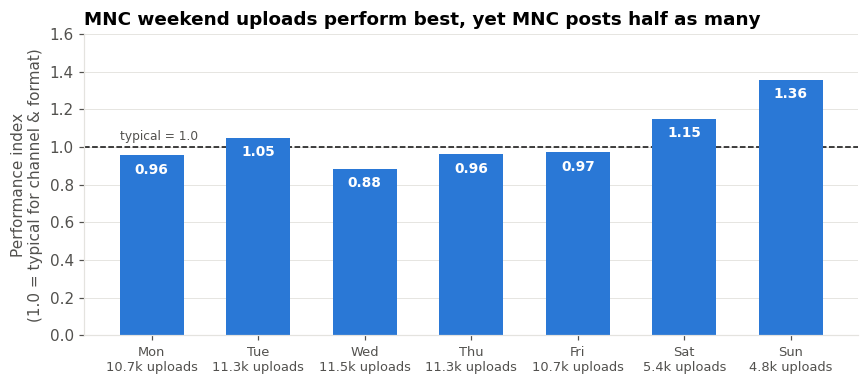

In [ ]:
d3 = p[p['group'] == 'MNC'].groupby(['dow_num', 'day_of_week']).agg(
    idx=('vpd_index2', 'median'), n=('video_id', 'size')).reset_index()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(range(7), d3['idx'], color=BLUE, width=0.6, zorder=2)
ax.axhline(1, color=INK, lw=1, ls='--', zorder=1)
ax.text(-0.3, 1.02, 'typical = 1.0', ha='left', va='bottom',
        fontsize=8, color=MUTED)
for i, val in enumerate(d3['idx']):
    ax.text(i, val - 0.04, f'{val:.2f}', ha='center', va='top',
            fontsize=9, color='white', fontweight='bold')
labels = [f"{d[:3]}\n{n / 1000:.1f}k uploads"
          for d, n in zip(d3['day_of_week'], d3['n'])]
ax.set_xticks(range(7), labels, fontsize=8.5)
ax.set_ylim(0, max(1.6, d3['idx'].max() + 0.2))
ax.set_ylabel('Performance index\n(1.0 = typical for channel & format)')
ax.grid(axis='x', visible=False)
ax.set_title('MNC weekend uploads perform best, yet MNC posts half as many')
save(fig, '03_mnc_upload_day.png')

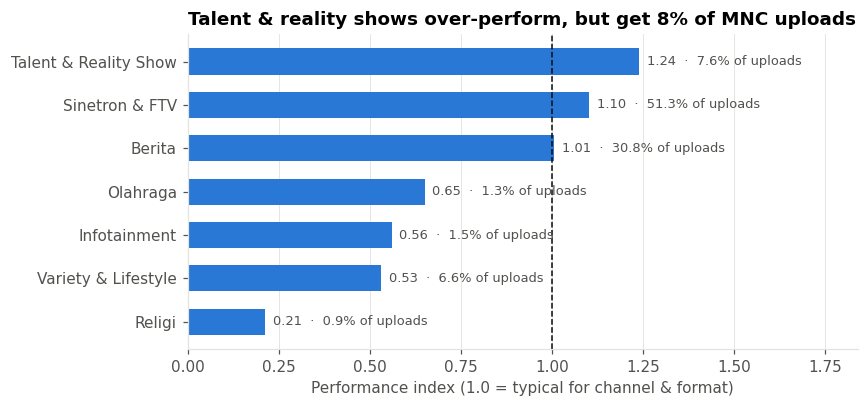

In [ ]:
gp = p[~p['content_genre'].isin(['Lainnya', 'Tidak teridentifikasi'])]
g4 = gp[gp['group'] == 'MNC'].groupby('content_genre').agg(
    idx=('vpd_index2', 'median'), n=('video_id', 'size'))
g4['share'] = g4['n'] / g4['n'].sum() * 100
g4 = g4.sort_values('idx')
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(range(len(g4)), g4['idx'], color=BLUE, height=0.6)
ax.axvline(1, color=INK, lw=1, ls='--')
for i, (val, sh) in enumerate(zip(g4['idx'], g4['share'])):
    ax.text(val + 0.02, i, f'{val:.2f}  ·  {sh:.1f}% of uploads',
            va='center', fontsize=8.5, color=MUTED)
ax.set_yticks(range(len(g4)), g4.index)
ax.set_xlim(0, max(1.8, g4['idx'].max() + 0.6))
ax.set_xlabel('Performance index (1.0 = typical for channel & format)')
ax.grid(axis='y', visible=False)
ax.set_title('Talent & reality shows over-perform, but get 8% of MNC uploads')
save(fig, '04_mnc_genre_index.png')

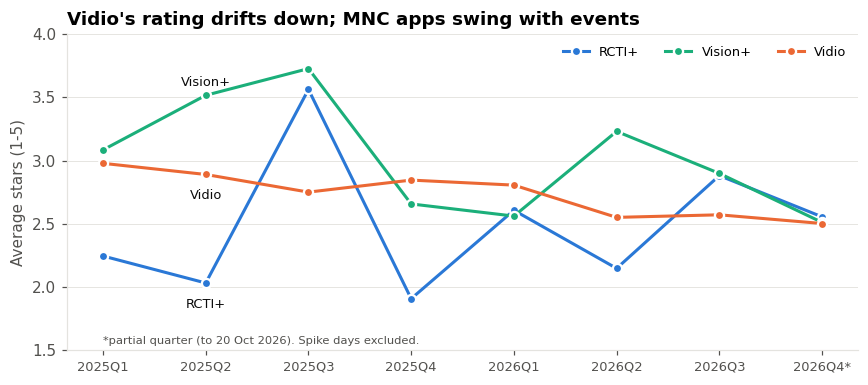

In [ ]:
q5 = nw.pivot_table(index='quarter', columns='app', values='score',
                    aggfunc='mean').sort_index()
x = range(len(q5))
fig, ax = plt.subplots(figsize=(8, 3.6))
for app in ['RCTIplus', 'Visionplus', 'Vidio']:
    ax.plot(x, q5[app], color=APP_C[app], lw=2, marker='o', ms=6,
            mec='white', mew=1.5, label=APP_NAME[app])
    off = {'Visionplus': 0.1, 'Vidio': -0.17, 'RCTIplus': -0.17}[app]
    ax.text(1, q5[app].iloc[1] + off, APP_NAME[app], ha='center',
            va='center', fontsize=8.5, color=INK)
ticks = [q if i < len(q5) - 1 else q + '*' for i, q in enumerate(q5.index)]
ax.set_xticks(x, ticks, fontsize=8.5)
ax.set_ylim(1.5, 4)
ax.set_ylabel('Average stars (1-5)')
ax.grid(axis='x', visible=False)
ax.set_title("Vidio's rating drifts down; MNC apps swing with events")
ax.legend(loc='upper right', ncol=3, fontsize=8.5)
ax.text(0, 1.55, '*partial quarter (to 20 Oct 2026). Spike days excluded.',
        fontsize=7.5, color=MUTED)
save(fig, '05_app_rating_quarterly.png')

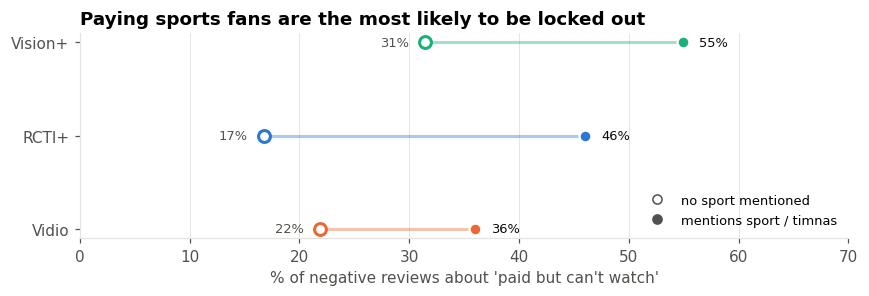

In [ ]:
s6 = neg.groupby(['app', 'mentions_sport'])['is_akses_setelah_bayar']
s6 = (s6.mean().unstack() * 100).loc[['Vidio', 'RCTIplus', 'Visionplus']]
fig, ax = plt.subplots(figsize=(8, 2.8))
for i, app in enumerate(s6.index):
    a, b, col = s6.loc[app, False], s6.loc[app, True], APP_C[app]
    ax.plot([a, b], [i, i], color=col, lw=2, alpha=0.4)
    ax.scatter(a, i, s=60, facecolor='white', edgecolor=col, lw=2, zorder=3)
    ax.scatter(b, i, s=60, color=col, edgecolor='white', lw=1.5, zorder=3)
    ax.text(a - 1.5, i, f'{a:.0f}%', ha='right', va='center',
            fontsize=8.5, color=MUTED)
    ax.text(b + 1.5, i, f'{b:.0f}%', ha='left', va='center',
            fontsize=8.5, color=INK)
ax.set_yticks(range(3), [APP_NAME[a] for a in s6.index])
ax.set_xlim(0, 70)
ax.set_xlabel("% of negative reviews about 'paid but can't watch'")
ax.grid(axis='y', visible=False)
ax.set_title('Paying sports fans are the most likely to be locked out')
leg = [Line2D([], [], marker='o', ls='', mfc='white', mec=MUTED,
              label='no sport mentioned'),
       Line2D([], [], marker='o', ls='', color=MUTED,
              label='mentions sport / timnas')]
ax.legend(handles=leg, loc='lower right', fontsize=8.5)
save(fig, '06_access_failure_sport.png')

In [ ]:
from google.colab import drive, files
drive.mount('/content/drive')
import pandas as pd
BASE = '/content/drive/MyDrive/mnc-analytics/'
v = pd.read_csv(BASE + 'clean/yt_videos_clean_tahap2.csv')
r = pd.read_csv(BASE + 'clean/app_reviews_clean.csv')
print(v.shape, r.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(106303, 37) (46649, 37)


In [ ]:
vs = v.rename(columns={'group': 'channel_group', 'date': 'publish_date',
                       'month': 'publish_month', 'hour': 'publish_hour'})
vs = vs[['video_id', 'channel_name', 'channel_group', 'format',
         'content_genre', 'published_wib', 'publish_date', 'publish_month',
         'dow_num', 'day_of_week', 'publish_hour', 'duration_sec', 'views',
         'likes', 'comments', 'engagement_rate', 'views_per_day',
         'exclude_perf', 'is_promo', 'is_outlier']].copy()
vs['duration_sec'] = vs['duration_sec'].round().astype('Int64')
vs['comments'] = vs['comments'].round().astype('Int64')
for c in ['exclude_perf', 'is_promo', 'is_outlier']:
    vs[c] = vs[c].astype(int)
vs.to_csv(BASE + 'final/sql_videos.csv', index=False, na_rep='\\N')
print(vs.shape, '| duplicate ids:', vs['video_id'].duplicated().sum())

(106303, 20) | duplicate ids: 0


In [ ]:
TOPIC = ['akses_setelah_bayar', 'pembayaran', 'paywall_harga', 'login_akun',
         'iklan', 'konten', 'error_crash', 'lag_buffering', 'gagal_putar',
         'tv_device']
rs = r.copy()
rs['review_dt'] = pd.to_datetime(rs['review_dt'])
rs['review_month'] = rs['review_dt'].dt.strftime('%Y-%m')
rs = rs[['review_id', 'app', 'score', 'review_dt', 'review_date',
         'review_month', 'replied', 'reply_hours', 'reply_is_template',
         'reply_time_invalid', 'app_version', 'app_version_major',
         'is_spike_day', 'spike_event_id', 'sentiment', 'complaint_topic',
         'mentions_sport'] + ['is_' + t for t in TOPIC]].copy()
for c in rs.columns:
    if rs[c].dtype == bool:
        rs[c] = rs[c].astype(int)
rs.to_csv(BASE + 'final/sql_reviews.csv', index=False, na_rep='\\N')
print(rs.shape, '| duplicate ids:', rs['review_id'].duplicated().sum(),
      '| longest id:', rs['review_id'].str.len().max())

files.download(BASE + 'final/sql_videos.csv')
files.download(BASE + 'final/sql_reviews.csv')

(46649, 27) | duplicate ids: 0 | longest id: 36


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>